# 01. Kiểm tra toàn vẹn dữ liệu (data audit)

Mục tiêu: trước khi tạo feature, xác nhận dữ liệu DATATHON nhất quán giữa các bảng, tìm các điểm bất thường và chốt **quy tắc làm sạch** (mục 2 của báo cáo).

Nội dung:
1. Khóa ngoại và bản ghi mồ côi
2. Đối chiếu tiền: `payment_value` với dòng hàng, doanh thu ngày với `sales.csv`
3. Trùng lặp, giá trị âm, thứ tự ngày, trạng thái đơn theo năm
4. Đơn vị tiền tệ
5. Nguyên nhân số đơn giảm từ 2019
6. Bảng quy tắc làm sạch

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")
from to_parquet import load_tables
from clean import clean_tables
from viz import C, INK, INK2, save

t = load_tables()
o, oi, p, pr = t["orders"], t["order_items"], t["payments"], t["products"]
c, sh, rt, rv, sales = t["customers"], t["shipments"], t["returns"], t["reviews"], t["sales"]
pd.DataFrame({k: [len(v), v.shape[1]] for k, v in t.items()}, index=["số dòng", "số cột"]).T

,số dòng,số cột
customers,121930,7
geography,39948,4
inventory,60247,17
order_items,714669,7
orders,646945,8
payments,646945,4
products,2412,8
promotions,50,10
returns,39939,7
reviews,113551,7


## 1. Khóa ngoại và bản ghi mồ côi

In [2]:
def orphans(child, key, parent, pkey=None):
    return int((~child[key].isin(parent[pkey or key])).sum())

fk = pd.DataFrame([
    ("orders.customer_id → customers", orphans(o, "customer_id", c)),
    ("orders.zip → geography", orphans(o, "zip", t["geography"])),
    ("customers.zip → geography", orphans(c, "zip", t["geography"])),
    ("order_items.order_id → orders", orphans(oi, "order_id", o)),
    ("order_items.product_id → products", orphans(oi, "product_id", pr)),
    ("order_items.promo_id → promotions", int((oi.promo_id.notna() & ~oi.promo_id.isin(t["promotions"].promo_id)).sum())),
    ("payments.order_id → orders", orphans(p, "order_id", o)),
    ("shipments.order_id → orders", orphans(sh, "order_id", o)),
    ("returns.order_id → orders", orphans(rt, "order_id", o)),
    ("reviews.order_id → orders", orphans(rv, "order_id", o)),
    ("orders không có order_items", orphans(o, "order_id", oi)),
    ("orders không có payment", orphans(o, "order_id", p)),
], columns=["quan hệ", "số bản ghi mồ côi"])
fk

,quan hệ,số bản ghi mồ côi
0,orders.customer_id → customers,0
1,orders.zip → geography,0
2,customers.zip → geography,0
3,order_items.order_id → orders,0
4,order_items.product_id → products,0
5,order_items.promo_id → promotions,0
6,payments.order_id → orders,0
7,shipments.order_id → orders,0
8,returns.order_id → orders,0
9,reviews.order_id → orders,0


In [3]:
print("Khách không có đơn nào:", (~c.customer_id.isin(o.customer_id)).sum(), "/", len(c))
oc = o.merge(c[["customer_id", "zip"]], on="customer_id", suffixes=("", "_c"))
print("Đơn có zip khác zip của khách:", (oc.zip != oc.zip_c).sum())
rv2 = rv.merge(o[["order_id", "customer_id"]], on="order_id", suffixes=("", "_o"))
print("Review có customer_id khác người đặt đơn:", (rv2.customer_id != rv2.customer_id_o).sum())
print("payment_method khác giữa payments và orders:",
      (p.set_index("order_id").payment_method != o.set_index("order_id").payment_method).sum())

Khách không có đơn nào: 31684 / 121930
Đơn có zip khác zip của khách: 0
Review có customer_id khác người đặt đơn: 0
payment_method khác giữa payments và orders: 0


**Nhận xét:** toàn bộ khóa ngoại khớp, không có bản ghi mồ côi. 31.684 khách (26%) chưa từng đặt đơn; các khách này tự động bị loại khỏi tập xét churn (định nghĩa yêu cầu có ít nhất một đơn hợp lệ trước mốc cắt).

## 2. Đối chiếu tiền

### 2.1 `payment_value` so với tổng dòng hàng

In [4]:
line = oi.quantity * oi.unit_price - oi.discount_amount
diff = p.set_index("order_id").payment_value - line.groupby(oi.order_id).sum()
print("Chênh lệch tuyệt đối lớn nhất:", diff.abs().max())
print("Số đơn lệch > 0,01:", (diff.abs() > 0.01).sum())

Chênh lệch tuyệt đối lớn nhất: 5.820766091346741e-11
Số đơn lệch > 0,01: 0


`payment_value = Σ(quantity × unit_price − discount_amount)` đúng tới sai số làm tròn số thực (1e-11). Phí vận chuyển (`shipments.shipping_fee`) **không** nằm trong `payment_value`.

### 2.2 Doanh thu theo ngày so với `sales.csv`

In [5]:
x = oi.merge(o[["order_id", "order_date", "order_status"]], on="order_id").merge(pr[["product_id", "cogs"]], on="product_id")
x["gross"] = x.quantity * x.unit_price
x["net"] = x.gross - x.discount_amount
x["cg"] = x.quantity * x.cogs
s = sales.set_index("Date")

def compare(mask, col):
    j = x[mask].groupby("order_date")[[col, "cg"]].sum().join(s, how="inner")
    r = j[col] / j.Revenue
    return pd.Series({"số ngày": len(j), "trung vị tỷ lệ": r.median(), "lệch lớn nhất": (r - 1).abs().max(),
                      "tỷ lệ COGS": (j.cg / j.COGS).median()})

all_ = x.order_status.notna()
valid = ~x.order_status.isin(["cancelled", "created"])
pd.DataFrame({
    "gross (qty×giá), mọi trạng thái": compare(all_, "gross"),
    "net (trừ giảm giá), mọi trạng thái": compare(all_, "net"),
    "net, chỉ đơn hợp lệ": compare(valid, "net"),
}).T.round(4)

,số ngày,trung vị tỷ lệ,lệch lớn nhất,tỷ lệ COGS
"gross (qty×giá), mọi trạng thái",3833.0,1.0000,0.0000,1.0000
"net (trừ giảm giá), mọi trạng thái",3833.0,1.0000,0.2000,1.0000
"net, chỉ đơn hợp lệ",3833.0,0.8708,0.4178,0.8991


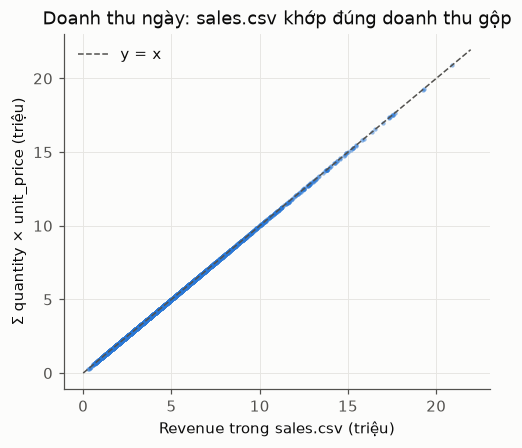

In [6]:
j = x.groupby("order_date")[["gross"]].sum().join(s)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(j.Revenue / 1e6, j.gross / 1e6, s=8, color=C[0], alpha=0.5, linewidths=0)
lim = [0, j.Revenue.max() / 1e6 * 1.05]
ax.plot(lim, lim, color=INK2, lw=1, ls="--", label="y = x")
ax.set(xlabel="Revenue trong sales.csv (triệu)", ylabel="Σ quantity × unit_price (triệu)",
       title="Doanh thu ngày: sales.csv khớp đúng doanh thu gộp")
ax.legend(frameon=False)
save(fig, "01_sales_reconcile")

**Nhận xét:** `sales.csv` (Revenue, COGS) = tổng `quantity × unit_price` và `quantity × cogs` của **mọi** đơn, kể cả đơn hủy, **trước** giảm giá. Đây là doanh thu gộp, không phải doanh thu thực thu.

→ Đồ án dùng định nghĩa riêng: doanh thu = `line_revenue` (đã trừ giảm giá) của đơn hợp lệ, trừ tiền hoàn. `sales.csv` chỉ dùng để xác nhận bảng giao dịch là đầy đủ (khớp 100% số ngày), không dùng làm nhãn.

## 3. Trùng lặp, giá trị âm, thứ tự ngày, trạng thái

In [7]:
rows = []
for k, d in t.items():
    num = d.select_dtypes("number")
    rows.append((k, int(d.duplicated().sum()), int((num < 0).sum().sum()), int(d.isna().sum().sum())))
pd.DataFrame(rows, columns=["bảng", "dòng trùng hoàn toàn", "số ô âm", "số ô rỗng"])

,bảng,dòng trùng hoàn toàn,số ô âm,số ô rỗng
0,customers,0,0,0
1,geography,0,0,0
2,inventory,0,0,0
3,order_items,0,0,1152816
4,orders,0,0,0
5,payments,0,0,0
6,products,0,0,0
7,promotions,0,0,40
8,returns,0,0,0
9,reviews,0,0,0


Không có dòng trùng hoàn toàn và không có giá trị âm. Ô rỗng chỉ nằm ở `promo_id`, `promo_id_2` (dòng không dùng khuyến mãi) và `promotions.applicable_category` (khuyến mãi áp cho mọi danh mục), đều có nghĩa, không phải dữ liệu thiếu.

In [8]:
dup = oi[oi.duplicated(["order_id", "product_id"], keep=False)].sort_values(["order_id", "product_id"])
print("Dòng hàng trùng (order_id, product_id):", oi.duplicated(["order_id", "product_id"]).sum())
dup.head(6)

Dòng hàng trùng (order_id, product_id): 16


,order_id,product_id,quantity,unit_price,discount_amount,promo_id,promo_id_2
12233,14280,976,1,4019.47,0.0,NaN,NaN
12234,14280,976,2,3937.99,0.0,NaN,NaN
99645,113379,786,6,694.34,0.0,NaN,NaN
99646,113379,786,1,699.37,0.0,NaN,NaN
189239,215525,1859,5,1896.11,0.0,NaN,NaN
189240,215525,1859,5,1897.20,0.0,NaN,NaN


In [9]:
sh2 = sh.merge(o[["order_id", "order_date", "order_status"]], on="order_id")
rt2 = rt.merge(o[["order_id", "order_date", "order_status"]], on="order_id")
rv3 = rv.merge(o[["order_id", "order_date", "order_status"]], on="order_id")
ri = rt.merge(oi.assign(line=line).groupby(["order_id", "product_id"], as_index=False).agg(q=("quantity", "sum"), line=("line", "sum")),
              on=["order_id", "product_id"])
checks = pd.Series({
    "ship_date < order_date": (sh2.ship_date < sh2.order_date).sum(),
    "delivery_date < ship_date": (sh2.delivery_date < sh2.ship_date).sum(),
    "return_date < order_date": (rt2.return_date < rt2.order_date).sum(),
    "review_date < order_date": (rv3.review_date < rv3.order_date).sum(),
    "return_quantity > quantity": (ri.return_quantity > ri.q).sum(),
    "refund_amount > doanh thu dòng": (ri.refund_amount > ri.line + 0.01).sum(),
    "đơn returned không có dòng returns": (~o[o.order_status == "returned"].order_id.isin(rt.order_id)).sum(),
    "đơn delivered/returned/shipped không có shipment": (~o[o.order_status.isin(["delivered", "returned", "shipped"])].order_id.isin(sh.order_id)).sum(),
})
print("Trạng thái của đơn có returns:", rt2.order_status.value_counts().to_dict())
print("Trạng thái của đơn có review:", rv3.order_status.value_counts().to_dict())
print("Số ngày đặt→gửi:", (sh2.ship_date - sh2.order_date).dt.days.agg(["min", "median", "max"]).to_dict(),
      "| gửi→nhận:", (sh2.delivery_date - sh2.ship_date).dt.days.agg(["min", "median", "max"]).to_dict())
checks.to_frame("số bản ghi")

Trạng thái của đơn có returns: {'returned': 39939}
Trạng thái của đơn có review: {'delivered': 113551}
Số ngày đặt→gửi: {'min': 0.0, 'median': 1.0, 'max': 3.0} | gửi→nhận: {'min': 2.0, 'median': 4.0, 'max': 7.0}


,số bản ghi
ship_date < order_date,0
delivery_date < ship_date,0
return_date < order_date,0
review_date < order_date,0
return_quantity > quantity,0
refund_amount > doanh thu dòng,4423
đơn returned không có dòng returns,80
đơn delivered/returned/shipped không có shipment,564


Đơn đặt trước ngày đăng ký: 73.8% số đơn
Tương quan ngày đăng ký và ngày đơn đầu tiên: r = 0.002


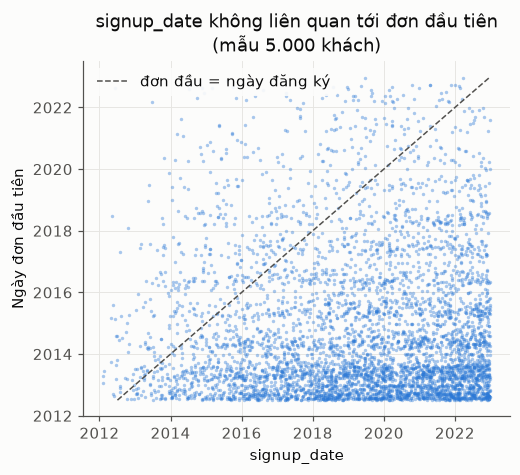

In [10]:
first = o.groupby("customer_id").order_date.min().to_frame("first_order").join(c.set_index("customer_id").signup_date)
gap = (first.first_order - first.signup_date).dt.days
print(f"Đơn đặt trước ngày đăng ký: {(o.merge(c[['customer_id','signup_date']], on='customer_id').eval('order_date < signup_date')).mean():.1%} số đơn")
print(f"Tương quan ngày đăng ký và ngày đơn đầu tiên: r = {np.corrcoef(first.first_order.astype('int64'), first.signup_date.astype('int64'))[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(5, 4.2))
smp = first.sample(5000, random_state=0)
ax.scatter(smp.signup_date, smp.first_order, s=5, color=C[0], alpha=0.4, linewidths=0)
ax.plot([first.first_order.min(), first.first_order.max()], [first.first_order.min(), first.first_order.max()],
        color=INK2, lw=1, ls="--", label="đơn đầu = ngày đăng ký")
ax.set(xlabel="signup_date", ylabel="Ngày đơn đầu tiên", title="signup_date không liên quan tới đơn đầu tiên\n(mẫu 5.000 khách)")
ax.legend(loc="upper left", framealpha=0.9, edgecolor="none")
save(fig, "01_signup_vs_first_order")

**Nhận xét:**
- Thứ tự ngày giao vận, đổi trả, đánh giá đều hợp lệ. Thời gian đặt→gửi 0–3 ngày, gửi→nhận 2–7 ngày (phân phối đều, đặc trưng dữ liệu sinh).
- **`signup_date` không dùng được:** 74% số đơn có ngày đặt **trước** ngày đăng ký, và ngày đăng ký gần như độc lập với ngày đơn đầu tiên (r ≈ 0). Thâm niên khách phải tính từ đơn hợp lệ đầu tiên.
- 11% bản ghi `returns` có `refund_amount` lớn hơn doanh thu thực của dòng hàng (tối đa 3,6 lần) → giới hạn tiền hoàn bằng doanh thu dòng.
- 16 cặp (order_id, product_id) xuất hiện hai lần với số lượng, đơn giá khác nhau. `payment_value` bằng tổng **cả hai** dòng nên đây là hai dòng hợp lệ, giữ nguyên.
- 80 đơn `returned` không có bản ghi `returns`, 564 đơn đã giao/đang giao không có `shipments`: tỷ lệ rất nhỏ, feature giao hàng và đổi trả của các đơn này để trống (NaN), không điền giá trị giả.

order_status,delivered,returned,shipped,paid,created,cancelled
order_date,,,,,,
2012,80.1,5.7,2.1,2.2,1.0,9.0
2013,80.1,5.6,1.9,2.0,1.1,9.2
2014,80.2,5.6,2.1,2.1,1.0,9.0
2015,80.1,5.6,2.0,2.0,1.0,9.3
2016,80.3,5.7,2.0,1.9,1.0,9.1
2017,80.4,5.6,2.0,1.9,0.9,9.1
2018,80.2,5.5,2.0,2.0,1.0,9.3
2019,79.9,5.5,2.1,2.1,1.1,9.3
2020,80.2,5.6,1.9,2.0,1.0,9.3


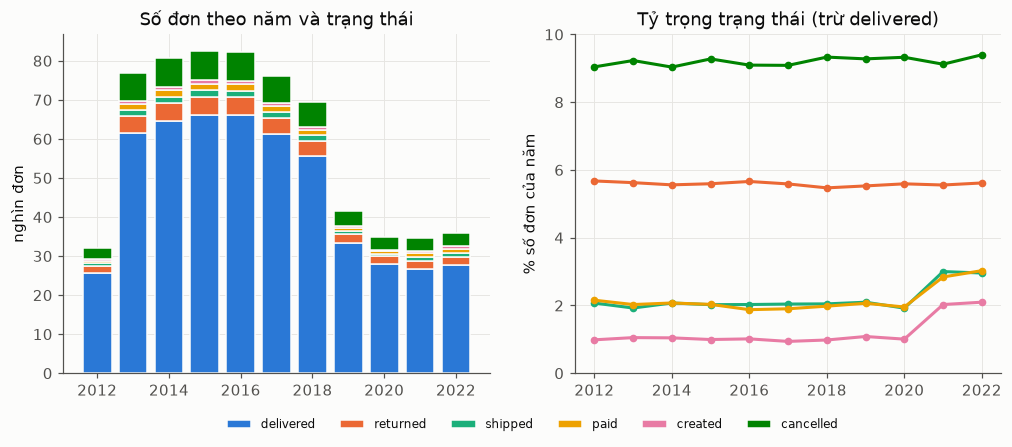

In [11]:
order_ = ["delivered", "returned", "shipped", "paid", "created", "cancelled"]
ct = pd.crosstab(o.order_date.dt.year, o.order_status)[order_]
share = ct.div(ct.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bottom = np.zeros(len(ct))
for i, st in enumerate(order_):
    axes[0].bar(ct.index, ct[st] / 1e3, bottom=bottom, color=C[i], label=st, width=0.8, edgecolor="#fcfcfb", linewidth=1)
    bottom += ct[st].values / 1e3
axes[0].set(title="Số đơn theo năm và trạng thái", ylabel="nghìn đơn")
axes[0].legend(frameon=False, ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(1.1, -0.1))
for i, st in enumerate(order_[1:], start=1):
    axes[1].plot(share.index, share[st] * 100, color=C[i], marker="o", ms=4, label=st)
axes[1].set(title="Tỷ trọng trạng thái (trừ delivered)", ylabel="% số đơn của năm")
axes[1].set_ylim(0, 10)
save(fig, "01_status_by_year")
(share * 100).round(1)

**Nhận xét:** tỷ trọng từng trạng thái gần như không đổi qua các năm (hủy ≈ 9%, trả hàng ≈ 5,6%); riêng 2021–2022 tỷ trọng `paid`, `shipped`, `created` nhích lên 2–3% mỗi loại. Các trạng thái "dở dang" (`paid`, `shipped`, `created`) xuất hiện đều ở mọi năm chứ không chỉ dồn về cuối 2022, tức là dữ liệu sinh không cập nhật trạng thái cuối. Vì vậy:
- `paid` và `shipped` được tính là một lần mua (khách đã trả tiền).
- `created` (chưa thanh toán) và `cancelled` không tính là mua, nhưng vẫn giữ lại để tính tỷ lệ hủy.

Năm 2012 chỉ có dữ liệu từ 04/07/2012, không so sánh trực tiếp tổng năm 2012 với các năm khác.

## 4. Đơn vị tiền tệ

           số_sp  giá_trung_vị  biên_LN_min  biên_LN_max
band                                                    
giá < 100    654        33.218         0.35         0.45
giá ≥ 100   1758      5606.055         0.05         0.50

Tên sản phẩm xuất hiện ở cả hai thang: 63
Phí ship: {'min': 0.0, '50%': 1.73, 'max': 32.0}
payment_value: {'min': 390.0, '50%': 17229.0, 'max': 331570.0}
unit_price / giá niêm yết: {'min': 0.462, '50%': 0.982, 'max': 1.104}


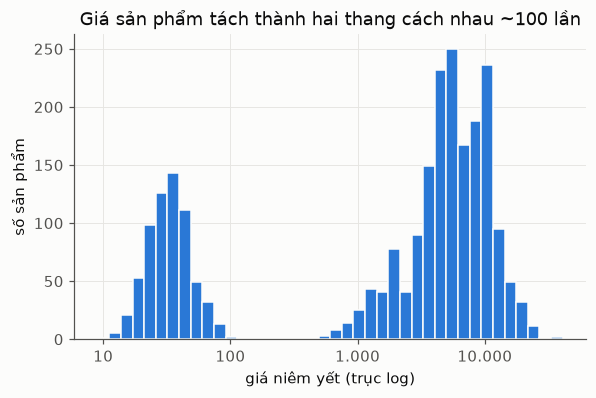

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(np.log10(pr.price), bins=40, color=C[0], edgecolor="#fcfcfb", linewidth=1)
ax.set(xlabel="giá niêm yết (trục log)", ylabel="số sản phẩm", title="Giá sản phẩm tách thành hai thang cách nhau ~100 lần")
ax.set_xticks([1, 2, 3, 4], ["10", "100", "1.000", "10.000"])
save(fig, "01_price_hist")

pr2 = pr.assign(band=np.where(pr.price < 100, "giá < 100", "giá ≥ 100"), margin=1 - pr.cogs / pr.price)
print(pr2.groupby("band").agg(số_sp=("price", "size"), giá_trung_vị=("price", "median"),
                              biên_LN_min=("margin", "min"), biên_LN_max=("margin", "max")).round(3))
print("\nTên sản phẩm xuất hiện ở cả hai thang:",
      pr2.groupby("product_name").band.nunique().gt(1).sum())
print("Phí ship:", sh.shipping_fee.describe()[["min", "50%", "max"]].to_dict())
print("payment_value:", p.payment_value.describe()[["min", "50%", "max"]].round(0).to_dict())
print("unit_price / giá niêm yết:", (oi.unit_price / oi.merge(pr, on="product_id").price.values).describe()[["min", "50%", "max"]].round(3).to_dict())

**Kết luận đơn vị tiền tệ: không xác định được, và cũng không cần xác định.**
- Giá sản phẩm tách thành hai thang lệch nhau khoảng 100 lần (27% sản phẩm giá 9–100, phần còn lại 1.000–41.000). Cùng một tên sản phẩm có thể ở cả hai thang. Hai thang còn có biên lợi nhuận khác nhau (thang nhỏ 35–45%, thang lớn 5–50%).
- Nếu là nghìn VND thì sản phẩm trung vị giá 4,4 triệu nhưng phí ship chỉ 1.730 đồng; nếu là VND thì phí ship 1,73 đồng. Không cách hiểu nào hợp lý cho mọi cột.
- Cả hai thang đều nhất quán với `payment_value` và `sales.csv`, nên **không quy đổi** (quy đổi sẽ làm sai doanh thu thật của bảng giao dịch).

→ Báo cáo ghi số tiền theo "đơn vị tiền của dataset". Các kết luận kinh doanh dùng **tỷ lệ và mức tăng tương đối**. Biên lợi nhuận gộp tính theo từng dòng hàng (`cogs` riêng từng sản phẩm), không bị ảnh hưởng bởi thang giá.

## 5. Vì sao số đơn giảm mạnh từ 2019?

In [13]:
v = o[~o.order_status.isin(["cancelled", "created"])].copy()
v["y"] = v.order_date.dt.year
v["fy"] = v.groupby("customer_id").order_date.transform("min").dt.year
active = v.groupby("y").customer_id.apply(set)
tab = pd.DataFrame({
    "đơn hợp lệ": v.groupby("y").size(),
    "khách mua": v.groupby("y").customer_id.nunique(),
    "khách mới (đơn đầu)": v[v.y == v.fy].groupby("y").customer_id.nunique(),
})
tab["khách cũ"] = tab["khách mua"] - tab["khách mới (đơn đầu)"]
tab["đơn / khách"] = tab["đơn hợp lệ"] / tab["khách mua"]
tab["giữ chân từ năm trước"] = [len(active[y] & active[y - 1]) / len(active[y - 1]) if y - 1 in active else np.nan for y in tab.index]
tab["giá trị đơn trung vị"] = v.merge(p, on="order_id").groupby("y").payment_value.median()
tab.round(3)

,đơn hợp lệ,khách mua,khách mới (đơn đầu),khách cũ,đơn / khách,giữ chân từ năm trước,giá trị đơn trung vị
y,,,,,,,
2012,28837,20433,20433,0,1.411,NaN,14533.140
2013,68948,37091,24290,12801,1.859,0.626,13573.765
2014,72516,38099,13262,24837,1.903,0.582,15362.095
2015,74135,38465,8778,29687,1.927,0.583,15200.220
2016,73933,38635,6423,32212,1.914,0.587,17796.130
2017,68389,37354,4810,32544,1.831,0.570,17786.610
2018,62342,35636,3725,31911,1.749,0.547,18871.305
2019,37290,25336,1900,23436,1.472,0.415,19290.535
2020,31277,22555,1532,21023,1.387,0.402,21275.830


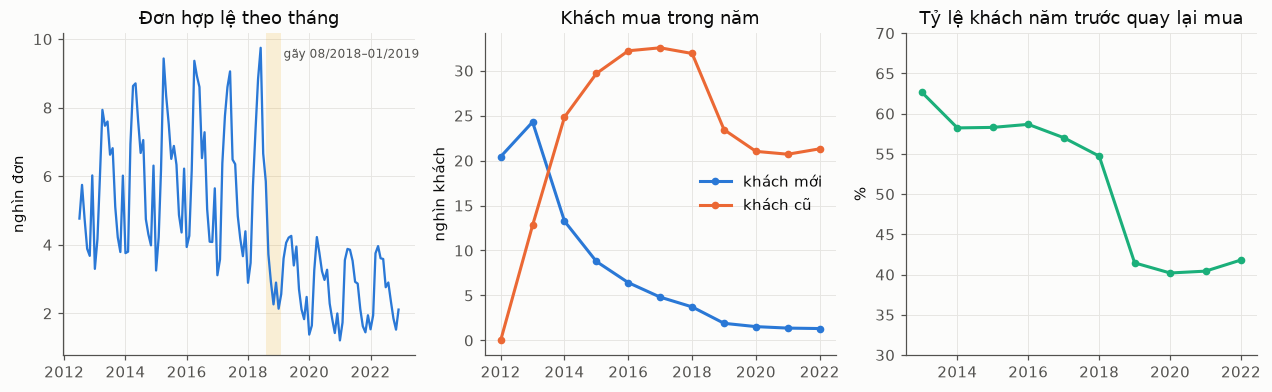

In [14]:
m = v.groupby(v.order_date.dt.to_period("M")).size()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(m.index.to_timestamp(), m.values / 1e3, color=C[0], lw=1.5)
axes[0].axvspan(pd.Timestamp("2018-08-01"), pd.Timestamp("2019-01-31"), color=C[3], alpha=0.15, lw=0)
axes[0].annotate("gãy 08/2018–01/2019", (pd.Timestamp("2019-03-01"), m.max() / 1e3 * 0.97), color=INK2, fontsize=8, ha="left")
axes[0].set(title="Đơn hợp lệ theo tháng", ylabel="nghìn đơn")

axes[1].plot(tab.index, tab["khách mới (đơn đầu)"] / 1e3, color=C[0], marker="o", ms=4, label="khách mới")
axes[1].plot(tab.index, tab["khách cũ"] / 1e3, color=C[1], marker="o", ms=4, label="khách cũ")
axes[1].set(title="Khách mua trong năm", ylabel="nghìn khách")
axes[1].legend(frameon=False)

axes[2].plot(tab.index[1:], tab["giữ chân từ năm trước"].iloc[1:] * 100, color=C[2], marker="o", ms=4)
axes[2].set(title="Tỷ lệ khách năm trước quay lại mua", ylabel="%")
axes[2].set_ylim(30, 70)
save(fig, "01_decline_cause")

**Nguyên nhân số đơn giảm: có hai cơ chế chồng lên nhau.**

1. **Khách mới cạn dần từ 2014** (24 nghìn năm 2013, chỉ còn 1,3 nghìn năm 2022). Giai đoạn 2014–2018, khách cũ bù lại nên tổng đơn vẫn ổn định. (Số khách đăng ký `signup_date` lại *tăng* đều mỗi năm, thêm bằng chứng cột này là nhiễu.)
2. **Một cú gãy cấu trúc trong khoảng 08/2018–01/2019:** số đơn có mùa vụ rõ (đỉnh tháng 4–6); đỉnh mùa giữ 9–9,7 nghìn đơn/tháng suốt 2015–2018, rồi sau 06/2018 rơi thẳng, và từ 2019 đỉnh mùa chỉ còn khoảng 4 nghìn (giảm hơn một nửa), không phục hồi. Tỷ lệ khách năm trước quay lại mua giảm từ ~57% xuống ~41% và giữ nguyên mức đó tới 2022. Số đơn trên mỗi khách cũng giảm (1,75 xuống 1,47).

Như vậy, **khách cũ mua ít đi** (giữ chân kém hơn) là nguyên nhân chính của cú giảm năm 2019, không phải chỉ do khách mới giảm. Giá trị đơn trung vị lại tăng đều, nên doanh thu giảm ít hơn số đơn.

**Hệ quả cho các task sau:**
- Mùa vụ mạnh nên Task 2 phải chọn mốc cắt cùng tháng trong năm khi so sánh, và cửa sổ nhãn W nên là bội số của 12 tháng.
- Từ 2019 trở đi là một chế độ (regime) ổn định: giữ chân ~41%, ~1,4 đơn/khách/năm. Tập validation (2021) và test (2022) đều nằm trong chế độ này.
- Mốc cắt train 2019-01 có feature tính từ giai đoạn trước cú gãy nhưng nhãn lại ở sau cú gãy. Task 2 cần so sánh tỷ lệ churn theo từng mốc cắt để quyết định có giữ mốc này không.
- Tỷ lệ churn kỳ vọng ở test ≈ 1 − 41% ≈ 59%: nhãn không quá lệch, PR-AUC vẫn là thước đo chính nhưng baseline của nó cao.

## 6. Quy tắc làm sạch

| # | Quy tắc | Lý do (bằng chứng ở mục) | Cài đặt |
| :--- | :--- | :--- | :--- |
| R1 | Đơn hợp lệ = trạng thái khác `cancelled`, `created`. `returned`, `paid`, `shipped` vẫn tính là một lần mua | Đơn hủy/chưa thanh toán không phải giao dịch; trạng thái dở dang có đều ở mọi năm (mục 3) | `orders.is_valid` |
| R2 | Doanh thu dòng = `quantity × unit_price − discount_amount`; giá vốn dòng = `quantity × cogs` | Khớp đúng `payment_value` (mục 2.1); `sales.csv` là doanh thu gộp nên không dùng (mục 2.2) | `order_items.line_revenue`, `line_cogs` |
| R3 | Giữ 16 dòng hàng trùng (order_id, product_id) | `payment_value` bằng tổng cả hai dòng (mục 3) | không đổi |
| R4 | Tiền hoàn = min(`refund_amount`, doanh thu dòng) | 11% bản ghi hoàn nhiều hơn số đã trả (mục 3) | `returns.refund_capped` |
| R5 | Bỏ `signup_date`; thâm niên tính từ đơn hợp lệ đầu tiên | 74% đơn đặt trước ngày đăng ký, r ≈ 0 (mục 3) | xóa cột |
| R6 | Không quy đổi giá; kết luận tiền dùng tỷ lệ | Hai thang giá đều khớp sổ sách, đơn vị không xác định (mục 4) | không đổi |
| R7 | Đơn thiếu `shipments`/`returns`: feature giao hàng, đổi trả để NaN | Tỷ lệ < 0,2%, không có căn cứ để điền (mục 3) | xử lý ở `features.py` |
| R8 | Khách không có đơn hợp lệ trước mốc cắt bị loại khỏi snapshot | Không có hành vi để dự báo; 26% khách chưa từng mua (mục 1) | xử lý ở `features.py` |
| R9 | `promo_id_2` giữ lại, chỉ dùng để đếm số khuyến mãi trên dòng | Chỉ 206 dòng, 2 mã | không đổi |
| R10 | `sales`, `web_traffic`, `inventory` chỉ dùng cho EDA | Không gắn với khách | không dùng trong feature |
| R11 | Lợi nhuận gộp dòng = doanh thu dòng − tiền hoàn − giá vốn × (số lượng − số lượng trả); dòng trùng chỉ nhận trả hàng một lần | CLV tính theo lợi nhuận; giả định hàng trả về bán lại được (bổ sung ở Task 2) | `order_items.gross_profit` |

Quy tắc R1–R5 và R11 được cài trong `ml/src/clean.py` (`clean_tables`), dùng chung cho mọi notebook sau.

In [15]:
tc = clean_tables(t)
print("Đơn hợp lệ:", tc["orders"].is_valid.sum(), "/", len(tc["orders"]))
print("Tổng tiền hoàn trước/sau giới hạn:", round(tc["returns"].refund_amount.sum()), "→", round(tc["returns"].refund_capped.sum()))
print("Cột của customers sau làm sạch:", list(tc["customers"].columns))
assert np.allclose(tc["order_items"].groupby("order_id").line_revenue.sum().reindex(p.order_id).values, p.payment_value.values)

Đơn hợp lệ: 580208 / 646945
Tổng tiền hoàn trước/sau giới hạn: 510598507 → 505980407
Cột của customers sau làm sạch: ['customer_id', 'zip', 'city', 'gender', 'age_group', 'acquisition_channel']
